# Stopping model: bound, guesses, and choice lapses

**Status (2026-10-09):** model implemented in `pigeon/stopping.py` (tests in
`tests/test_stopping.py`); parameter recovery below. Not yet fit to real data.

## Why this notebook

Every bound analysis in the paper treats each trial as a bound crossing and handles
guessing only by filtering (`DT >= 2`, `trial_number >= 10`, the `rt_below_cutoff`
from `get_bounds`). This notebook fits an explicit trial-level model of *when*
subjects stop and *which* side they choose, so that guesses are estimated rather
than filtered.

**Why not accuracy or congruence.** With Gaussian steps of mean ±μ, the
likelihood ratio for "right" vs. "left" depends only on the current position `x`.
So for a subject who chooses the side the pigeon is on, P(correct | x at commit)
= logistic(2μ|x|/σ²), *whatever* rule decided when to stop. Accuracy (and
congruence) therefore cannot separate a low bound from evidence-independent
stopping; only the timing of commitments can. A bound-based rule and a
random-timing rule both give accuracy that rises with SNR and with commit time
(see `scratchpad/acc_policy.py` from the 2026-10-09 session).

## Task facts the model relies on

- Steps are Gaussian: `move_pigeon_function` in both `task/OL-MX-PD/PigeonTask.js`
  and `task/MXSC/PigeonTask.js` draws `step_mean + step_std * N(0, 1)` (Marsaglia
  polar method).
- `steps` records the *displayed* position, clamped at ±0.75 (`EDGE_DISTANCE`);
  the walk itself is not clamped. Once at the wall the pigeon stays at the edge
  until the key press, so a long RT after a wall hit says nothing about stopping.
  Wall hits are common in OL/MX (11–14% of trials) and rare in MXSC (49 trials).
- A response is possible on the trial's first frame, before any step (RT = 1):
  14% of OL trials, 11% of MX, 2% of MXSC. These are commits with no evidence
  (anticipations).
- **Datasets:** OL, MX and MXSC. Not PD: there the bound is set before the trial,
  so there is no voluntary stopping to model.

## Model

Notation: `x_k` is the pigeon's position after `k` steps (`x_0 = 0`), and
`M_k = max_{j<=k} |x_j|` is the farthest it has been from center so far.

### Stopping

0. **Anticipation.** With probability `a` the subject commits before any step is
   shown (choice random; response within the first NDT + 1 frames).
1. **Variable bound.** Each trial draws its own bound `b ~ Gamma` with mean `θ`
   and SD `σ_b`, with CDF `F`. The subject commits at the first `k` with
   `|x_k| >= b`, so

   P(bound commit at k | path) = F(|x_k|) − F(M_{k−1}) if |x_k| > M_{k−1}, else 0.

   A bound can only fire when the pigeon reaches a new maximum distance from center.
2. **Guess.** Independently, at every step `k >= 1`
   the subject commits with probability `g`, regardless of the evidence.

### Choice

The subject chooses the side the pigeon is on at the commit step, `sign(x_k)`,
except with probability `ε` the choice is random. At `x_0 = 0` the choice is random.

### Motor delay (NDT)

The response comes `NDT + 1` steps after the commit step, so `k = RT − NDT − 1`
(the existing `DT` convention). NDT ∈ {1, 2, 3} with per-subject probabilities
`p_1, p_2, p_3`, shared across that subject's blocks. Each trial's likelihood
averages over NDT.

### Parameters (per subject)

| Part | Parameter | Meaning | Units / range |
|---|---|---|---|
| Bound | `θ` | mean bound across trials | position (same units as `bound`) |
| Bound | `σ_b` | SD of the bound across trials | position |
| Guess | `g` | per-step probability of an evidence-independent commit | 0–1 |
| Anticipation | `a` | probability of committing before any step | 0–1 |
| Choice | `ε` | probability of a random choice | 0–1 |
| Motor delay | `p_1, p_2, p_3` | P(NDT = 1, 2, 3); 2 free values | probabilities |

Bound, guess, anticipation and lapse parameters are per block; NDT is shared.
Fit on transformed scales (log `θ`, log `σ_b`, logit `g`, logit `ε`, softmax `p`).

### Change-point blocks

`θ` (optionally `σ_b`, `g`) takes separate pre- and post-CP values; positions from
the CP step on use the post values. Each trial keeps its bound *percentile*
across the CP: equivalently, draw `u ~ U(0, 1)` per trial and commit at the first
`k` with `F_k(|x_k|) >= u`, so P(bound commit at k) = max(F_k(|x_k|) − max_{j<k} F_j(|x_j|), 0).
The CP test is `θ_post` vs. `θ_pre` within LowHigh and HighLow, compared with a
simulated no-change null.

### Deliberately left out (add only if the fits need them)

- A ceiling on the stopping rate: the soft ceiling seen in the raw hazard may come
  from steps that are not new maxima, which the model already handles.
- Urgency (a bound that changes with time in the trial).
- Separate random-choice rates for guesses and bound commits.

### Wall-hit trials

A wall trial answered later than any NDT allows (RT > wall step + 4) is
censored: it contributes P(no commit before the wall) × P(choice at the wall).
Wall trials answered within that window use the ordinary likelihood.

### Trial selection

All trials with `trial_number >= 10`; **no DT cutoff** (short trials are what the
guess component models). Wall-hit trials are counted and reported, not silently
dropped. No bias correction: the model uses raw positions, so overshoot is part of
the likelihood.

## Plan

1. **Implementation:** likelihood, simulator, and fitter in `pigeon` (new module),
   with tests.
2. **Parameter recovery:** simulate with known parameters at each dataset's trial
   counts and step statistics; confirm the fit recovers them, especially `g` vs.
   the low tail of the bound (`σ_b`), and `θ_pre` vs. `θ_post`.
3. **Fixed blocks (OL, MX, MXSC Low/High):** how large are `g` and `ε`? Does the
   model reproduce RT distributions, accuracy, the CAF and congruence-by-lag?
   Does `DT >= 2` remove most guess commits?
4. **Change-point blocks:** `θ_post − θ_pre` per subject in LowHigh and HighLow,
   with a simulated null and an instant-adaptation power check.
5. **Decision:** whether guessing must be built into the bias correction, RR
   matrices and null models, or whether the DT cutoff is enough.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pigeon import get_data_table, fit_stopping_model, simulate_stopping_trials


## Parameter recovery at MXSC trial counts

Simulated subjects with the MXSC 2026 design and each block's median real trial
count (after `trial_number >= 10`): Low 71, High 118, LowHigh 74 (CP step 9),
HighLow 132 (CP step 6); step SD 0.05, step means 0.01/0.03. True parameters are
drawn per subject over plausible ranges; LowHigh and HighLow get an independent
true post-CP bound shift of up to ±40% of the bound mean. Each subject is fit
with all four blocks together (`post_params=('bound_mean',)`), as the real data
will be. Fixed-block parameters are averaged over blocks 1–2, which share the
true values.

In [2]:
SEED = 7
N_SIM_SUBJ = 40
STEP_STD = 0.05
# block: (n trials, pre step mean, post step mean, CP step)
SIM_BLOCKS = {1: (71, 0.01, None, 0), 2: (118, 0.03, None, 0),
              3: (74, 0.01, 0.03, 9), 4: (132, 0.03, 0.01, 6)}

rng = np.random.default_rng(SEED)
rows = []
for si in range(N_SIM_SUBJ):
    true = dict(bound_mean=rng.uniform(0.08, 0.30), guess_rate=rng.uniform(0.005, 0.08),
                lapse_rate=rng.uniform(0.01, 0.15), anticipation_rate=rng.uniform(0.005, 0.08))
    true['bound_std'] = true['bound_mean'] * rng.uniform(0.2, 0.8)
    ndt_probs = rng.dirichlet([4, 2, 1])
    shift = {3: true['bound_mean'] * rng.uniform(-0.4, 0.4), 4: true['bound_mean'] * rng.uniform(-0.4, 0.4)}
    sim = []
    for bi, (n, m_pre, m_post, cp) in SIM_BLOCKS.items():
        d = simulate_stopping_trials(n, m_pre, STEP_STD, ndt_probs=ndt_probs, change_point=cp,
                                     generative_mean_post=m_post,
                                     bound_mean_post=true['bound_mean'] + shift[bi] if cp else None,
                                     rng=rng, **true)
        sim.append(d.assign(block_index=bi))
    fit = fit_stopping_model(pd.concat(sim, ignore_index=True), post_params=('bound_mean',))
    p = fit['params'].set_index('group')
    row = {'subject': si, 'converged': fit['success'], 'true_ndt1': ndt_probs[0], 'fit_ndt1': fit['ndt_probs'][1]}
    for name, val in true.items():
        row[f'true_{name}'] = val
        row[f'fit_{name}'] = p.loc[[1, 2], name].mean()
    for bi in (3, 4):
        row[f'true_shift_{bi}'] = shift[bi]
        row[f'fit_shift_{bi}'] = p.loc[bi, 'bound_mean_post'] - p.loc[bi, 'bound_mean']
    rows.append(row)
recovery = pd.DataFrame(rows)
print(f"converged: {recovery.converged.sum()}/{len(recovery)}")

converged: 40/40


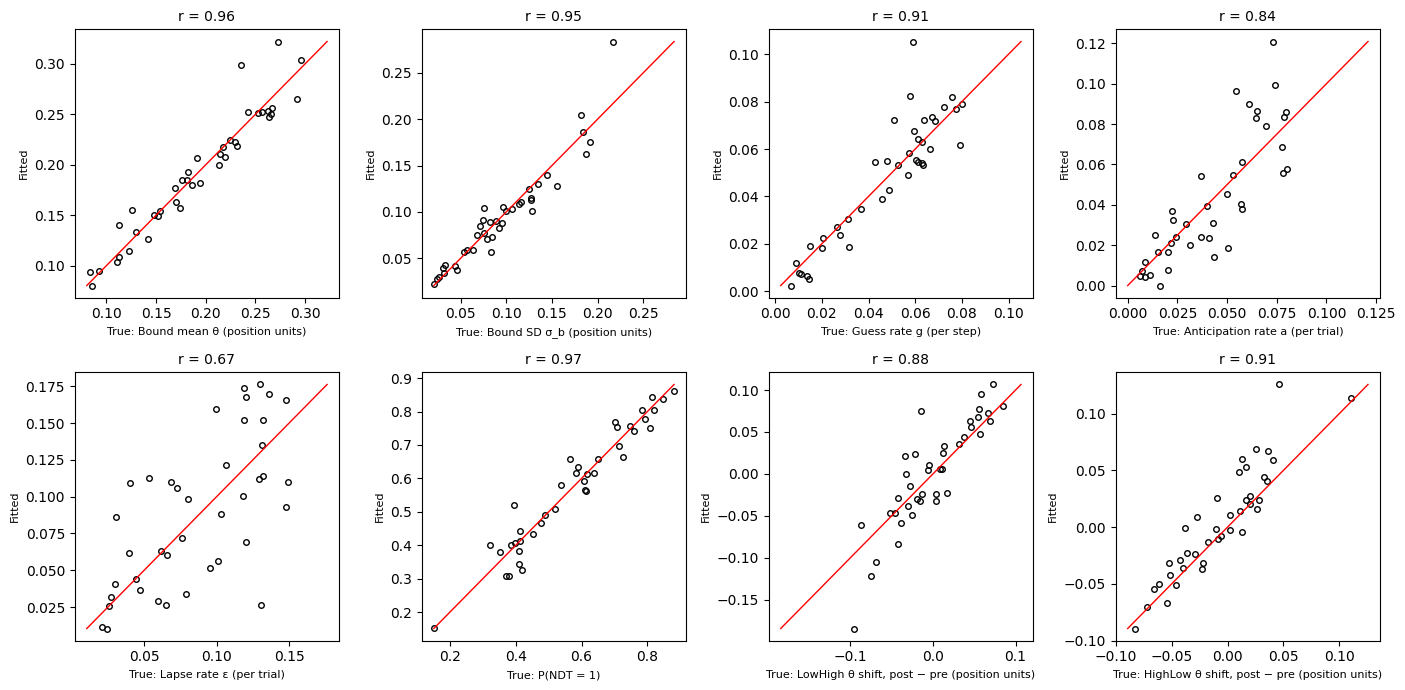

,parameter,r,median error,median |error|
0,bound_mean,0.9592,-0.0036,0.0086
1,bound_std,0.9508,0.0004,0.0069
2,guess_rate,0.9115,-0.0006,0.0057
3,anticipation_rate,0.8388,-0.0004,0.0113
4,lapse_rate,0.6678,0.0008,0.0265
5,ndt1,0.9668,-0.0057,0.0236
6,shift_3,0.8801,0.0052,0.0161
7,shift_4,0.9138,0.0075,0.0100


In [3]:
RECOVERY_PANELS = [
    ('bound_mean', 'Bound mean θ (position units)'),
    ('bound_std', 'Bound SD σ_b (position units)'),
    ('guess_rate', 'Guess rate g (per step)'),
    ('anticipation_rate', 'Anticipation rate a (per trial)'),
    ('lapse_rate', 'Lapse rate ε (per trial)'),
    ('ndt1', 'P(NDT = 1)'),
    ('shift_3', 'LowHigh θ shift, post − pre (position units)'),
    ('shift_4', 'HighLow θ shift, post − pre (position units)'),
]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
summary = []
for ax, (name, label) in zip(axes.flat, RECOVERY_PANELS):
    t, f = recovery[f'true_{name}'], recovery[f'fit_{name}']
    ax.plot(t, f, 'o', mfc='none', color='k', ms=4)
    lims = [min(t.min(), f.min()), max(t.max(), f.max())]
    ax.plot(lims, lims, 'r-', lw=1)
    r = np.corrcoef(t, f)[0, 1]
    ax.set_title(f'r = {r:.2f}', fontsize=10)
    ax.set_xlabel(f'True: {label}', fontsize=8)
    ax.set_ylabel('Fitted', fontsize=8)
    summary.append({'parameter': name, 'r': r, 'median error': np.median(f - t),
                    'median |error|': np.median(np.abs(f - t))})
plt.tight_layout()
plt.show()
pd.DataFrame(summary).round(4)

**Recovery (2026-10-09, 40 simulated subjects).** Bound mean, bound SD, guess rate
and NDT recover well (r ≈ 0.92–0.97), so guesses and low bounds separate at
these trial counts. The post-CP bound shift recovers with r ≈ 0.9 and a typical
error of ~0.01–0.015 position units, despite only ~20 post-CP commits per
subject per block. The lapse rate is the weakest (r ≈ 0.7), so treat individual
lapse estimates with caution.

These results assume the model is correct; the next step is checking how well
it describes the real data.